# 01 · Returns and risk: how to read a result

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/01_returns_and_risk.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

Before you can judge a trading strategy you need to read a result: how much did it make, how bumpy was the ride, and how bad was the worst fall? This notebook builds those numbers by hand on SPY. **No strategy yet.** Buy and hold is the only thing we measure.

**What you'll do (~60 min):**
1. Turn prices into **returns**
2. See why returns **compound**
3. Measure risk two ways: **volatility** and **drawdown**
4. Measure return per unit of risk with the **Sharpe ratio**
5. See why averages hide the bad years
6. Put it together in a scorecard that every later strategy is held up against

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. From prices to returns

A price on its own says little: a rise from $10 to $11 and a rise from $500 to $501 are very different. A **return** is the percentage change, so it means the same thing for any price.

`pct_change()` works out each day's percentage change in the closing price. The first day has no day before it, so we drop it.

In [2]:
from backtester import load_prices

spy = load_prices("SPY")
close = spy["Close"]
returns = close.pct_change().dropna()
returns.head()

Date
2016-01-05    0.0017
2016-01-06   -0.0126
2016-01-07   -0.0240
2016-01-08   -0.0110
2016-01-11    0.0010
Name: Close, dtype: float64

`describe()` summarises all the daily returns: how many there are, the average, how spread out they are (`std`) and the extremes. Notice how small the average is next to the spread. A typical day moves a lot more than the average day gains.

In [3]:
returns.describe()

count    2707.0000
mean        0.0006
std         0.0111
min        -0.1094
25%        -0.0036
50%         0.0007
75%         0.0059
max         0.1050
Name: Close, dtype: float64

**Predict first:** can you guess the dates of the best and the worst day? Then run the cell.

In [4]:
print(f"Worst day: {returns.idxmin():%Y-%m-%d}  {returns.min():.1%}")
print(f"Best day:  {returns.idxmax():%Y-%m-%d}  {returns.max():.1%}")

Worst day: 2020-03-16  -10.9%
Best day:  2025-04-09  10.5%


## 2. Returns compound

Returns **multiply**, they do not add. Gain 50% and then lose 50% and you are not back to even:

In [5]:
(1 + 0.50) * (1 - 0.50) - 1

-0.25

You are 25% down. The same thing happens day after day, so to find what $10,000 became we multiply together (1 + each day's return). `cumprod()` does that running multiplication, and gives the value on every day. We put the starting $10,000 on day one by letting the first day's return be zero.

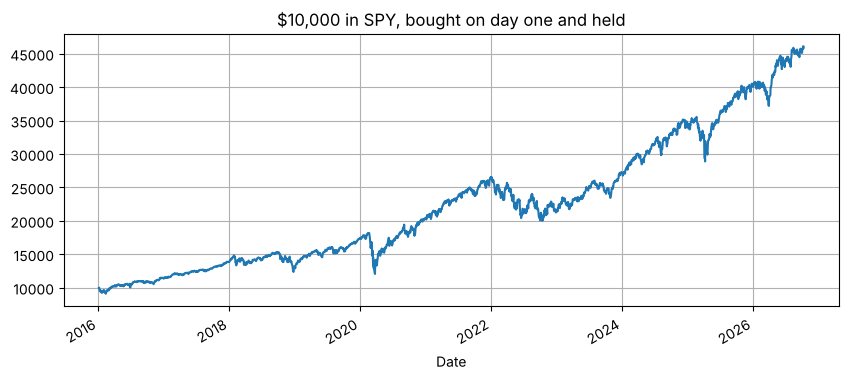

Ends at $46,055


In [6]:
daily = close.pct_change().fillna(0)
growth = 10_000 * (1 + daily).cumprod()
growth.plot(figsize=(10, 4), title="$10,000 in SPY, bought on day one and held", grid=True)
plt.show()
print(f"Ends at ${growth.iloc[-1]:,.0f}")

## 3. Risk, part one: volatility

**Volatility** is how much returns bounce around: the standard deviation of daily returns. We scale it to a year by multiplying by the square root of 252, the number of trading days in a year. A volatility of 18% a year means a typical year's return lands within about 18 points either side of the average.

The cell below computes it for SPY and compares it with the **yearly growth** (CAGR), the steady yearly return that would give the same end result.

In [7]:
from backtester.metrics import annual_volatility, cagr

print(f"SPY volatility:    {annual_volatility(returns):.1%} a year")
print(f"SPY yearly growth: {cagr(growth):.1%} a year")

SPY volatility:    17.7% a year
SPY yearly growth: 15.3% a year


## 4. Risk, part two: drawdown

Volatility counts ups and downs the same. An investor does not. What hurts is **drawdown**: how far the value has fallen below its highest point so far. It is 0 on a new high and -20% when you are 20% below the peak. The lowest it ever gets is the **maximum drawdown**, the worst fall you would have sat through.

`drawdown_series` works it out for every day. The red picture is the one to remember: it shows how deep each fall went and how long it lasted.

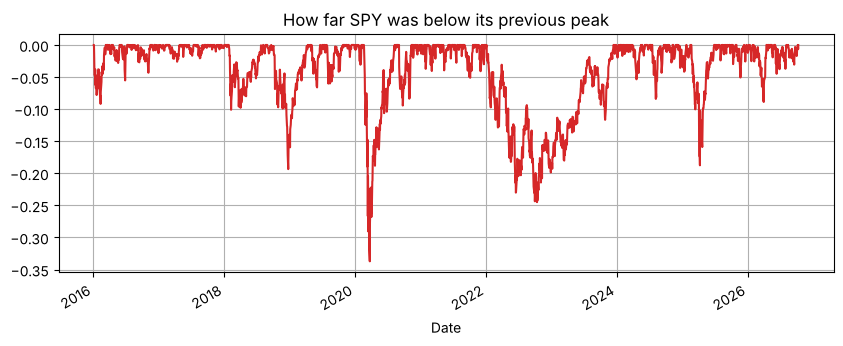

Worst fall: -33.7%, bottoming on 2020-03-23


In [8]:
from backtester.metrics import drawdown_series, max_drawdown

drawdown = drawdown_series(growth)
drawdown.plot(figsize=(10, 3.5), color="tab:red", title="How far SPY was below its previous peak", grid=True)
plt.show()
print(f"Worst fall: {max_drawdown(growth):.1%}, bottoming on {drawdown.idxmin():%Y-%m-%d}")

A fall is not over until the old peak is regained. The cell below finds the longest stretch of days spent below a previous peak. Being down for that long is the part people forget when they say "it always comes back".

In [9]:
below = drawdown < 0
longest = below.groupby((~below).cumsum()).sum().max()
print(f"Longest stretch below a previous peak: {longest} trading days, about {longest / 252:.1f} years")

Longest stretch below a previous peak: 488 trading days, about 1.9 years


The two crises in this data set are the 2020 Covid crash and the 2022 bear market. `crisis_table` shows what holding SPY did inside each window. You will see the same two windows again whenever a risk rule is tested.

In [10]:
from backtester.risk import crisis_table

crisis_table({"SPY, bought and held": growth})

,,Return,Worst fall
Crisis,Portfolio,,
2020 Covid crash,"SPY, bought and held",1.1%,-33.7%
2022 bear market,"SPY, bought and held",-18.6%,-24.5%


## 5. Return per unit of risk: the Sharpe ratio

Which is better, 12% a year with big swings or 9% with small ones? The **Sharpe ratio** answers by asking how much extra return you earned for each unit of volatility. Extra means above what **cash** would have paid, because you could have earned that with no risk at all.

> Sharpe = (average return above cash ÷ volatility), scaled to a year

In this workshop cash pays a flat **3% a year**. That is a rough average: cash paid close to nothing in 2020 and 2021 and nearer 5% in 2023. Using 0% would flatter every strategy. The cell shows both for SPY.

In [11]:
from backtester.metrics import sharpe_ratio

print(f"Sharpe with cash at 0%: {sharpe_ratio(returns):.2f}")
print(f"Sharpe with cash at 3%: {sharpe_ratio(returns, risk_free_rate=0.03):.2f}")

Sharpe with cash at 0%: 0.89
Sharpe with cash at 3%: 0.73


Assuming cash pays nothing makes the same performance look better. From here on we measure above 3%.

Now compare six very different funds on one page. `TLT` holds long US government bonds, `GLD` holds gold, `XLU` holds utility companies, `QQQ` holds the Nasdaq-100 and `AAPL` is a single company.

In [12]:
from backtester.metrics import cagr, sharpe_ratio

rows = {}
for ticker in ["SPY", "QQQ", "TLT", "GLD", "XLU", "AAPL"]:
    daily_t = load_prices(ticker)["Close"].pct_change().fillna(0)
    growth_t = (1 + daily_t).cumprod()
    rows[ticker] = {
        "Yearly growth": cagr(growth_t),
        "Volatility": annual_volatility(daily_t.iloc[1:]),
        "Worst fall": max_drawdown(growth_t),
        "Sharpe (cash 3%)": sharpe_ratio(daily_t.iloc[1:], risk_free_rate=0.03),
    }
table = pd.DataFrame(rows).T
table.style.format({"Yearly growth": "{:.1%}", "Volatility": "{:.1%}", "Worst fall": "{:.1%}", "Sharpe (cash 3%)": "{:.2f}"})

,Yearly growth,Volatility,Worst fall,Sharpe (cash 3%)
SPY,15.3%,17.7%,-33.7%,0.73
QQQ,20.5%,22.2%,-35.1%,0.82
TLT,-1.3%,14.7%,-48.4%,-0.22
GLD,13.1%,16.5%,-26.4%,0.65
XLU,9.7%,19.0%,-36.1%,0.43
AAPL,28.0%,28.9%,-38.5%,0.90


**What to notice:**
- The single company, AAPL, grew fastest and was bumpiest of the six. A big return rarely comes free.
- The long bond fund, TLT, had the deepest fall of the six and a negative Sharpe ratio: it earned less than cash for the risk. "Bonds are safe" was not true in 2022.
- The Sharpe ratio puts all six on one scale, which volatility and growth alone cannot do.

## 6. Averages hide the bad years

A yearly growth of 15% sounds smooth. It is made of years like these. Group the daily returns by calendar year and compound each group:

In [13]:
by_year = (1 + returns).groupby(returns.index.year).prod() - 1
by_year.to_frame("SPY return").style.format("{:+.1%}")

,SPY return
Date,
2016,+13.6%
2017,+21.7%
2018,-4.6%
2019,+31.2%
2020,+18.3%
2021,+28.7%
2022,-18.2%
2023,+26.2%
2024,+24.9%


Two years lost money, and the last row is only part of a year because the data ends in October. Smooth averages are a way of forgetting the years you would have wanted to sell.

## 7. Buy and hold is the bar

Here are all five numbers for SPY in one table. This is the **scorecard**. From session 5 on, every strategy is shown next to buy and hold's scorecard, and a strategy that cannot beat it on the measures you care about has not earned its complexity.

In [14]:
from backtester.metrics import compute_metrics, format_metrics

metrics = compute_metrics(growth, returns, risk_free_rate=0.03)
keep = {name: value for name, value in metrics.items() if name not in ("Number of trades", "Win rate")}
pd.Series(format_metrics(keep), name="SPY buy and hold")

Total return            360.6%
Annual return (CAGR)     15.3%
Annual volatility        17.7%
Sharpe ratio              0.73
Max drawdown            -33.7%
Name: SPY buy and hold, dtype: str

## 8. ✏️ Your turn

1. Change `"SPY"` in the cell below to `"TLT"`, `"GLD"` or `"AAPL"` and re-run. Does the scorecard match your guess?
2. Change the dates to look at only 2022. What is the worst fall inside that year alone?
3. Which ticker would you pick if you hated big falls? Which if you only cared about growth? Is there a ticker that wins on both?

In [15]:
ticker = "SPY"
start, end = None, None

my_close = load_prices(ticker, start, end)["Close"]
my_daily = my_close.pct_change().fillna(0)
my_growth = 10_000 * (1 + my_daily).cumprod()
my_metrics = compute_metrics(my_growth, my_daily.iloc[1:], risk_free_rate=0.03)
my_keep = {name: value for name, value in my_metrics.items() if name not in ("Number of trades", "Win rate")}
pd.Series(format_metrics(my_keep), name=f"{ticker} buy and hold")

Total return            360.6%
Annual return (CAGR)     15.3%
Annual volatility        17.7%
Sharpe ratio              0.73
Max drawdown            -33.7%
Name: SPY buy and hold, dtype: str

**Check yourself:**
- Fund A grew 12% a year with a worst fall of -40%. Fund B grew 9% a year with a worst fall of -15%. Which would you choose, and what would change your mind?
- Why can a strategy have a high average return and still be a bad one to own?
- Why does measuring Sharpe above 3% cash make strategies look worse than measuring it above 0%?

**Take-home:** the [trading dashboard project](https://github.com/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/take_home_dashboard.ipynb) has you write each of these measures yourself, as functions with self-checks, and turn them into a web page.

> Educational use only. Simulated results on historical data; not financial advice.

### Next: how a backtest can lie

Before we test any real strategy, we learn the five ways a backtest fools you, using strategies that have no skill at all.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/02_backtest_honesty.ipynb) `02_backtest_honesty.ipynb`